# Emotional Analysis of UK Parliamentary Immigration Debates (2023–2025)

**Research Question:** Do the Conservative and Labour parties differ in emotional tone (valence) and emotional intensity (arousal) when discussing immigration in UK parliamentary debates, and how does the July 2024 institutional shift influence this intensity?

**Keywords:** `immigration`, `migrant`, `asylum`  
**Data source:** mySociety ParlParse XML + UK Parliament Members API  
**Methods:** VADER (valence) · NRC-VAD v2.1 (arousal, dominance) · Mann-Whitney U test

---
### Notebook Structure
1. Install & import libraries
2. Fetch MP → Party mapping
3. Discover & download XML debate files
4. Parse XML with keyword filter
5. Match speakers to parties
6. Manual party corrections
7. VADER sentiment analysis
8. NRC-VAD arousal & dominance analysis
9. Institutional shift analysis (pre/post July 2024)
10. Visualisation
11. Save final dataset

## 1. Install & Import Libraries

In [2]:
# Uncomment to install if needed
# !pip install requests pandas beautifulsoup4 lxml vaderSentiment nltk

import requests
import pandas as pd
import numpy as np
import xml.etree.ElementTree as ET
from bs4 import BeautifulSoup
import re
import time
import json
from collections import Counter
from scipy import stats
import matplotlib.pyplot as plt

import nltk
nltk.download('punkt',    quiet=True)
nltk.download('punkt_tab',quiet=True)
nltk.download('stopwords',quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

print('✅ All libraries imported successfully.')

✅ All libraries imported successfully.


## 2. Fetch MP → Party Mapping
We query the official UK Parliament Members API to build a name→party dictionary for both current and former MPs.

In [4]:
def fetch_party_map():
    """Fetch all current and former Commons MPs and return {name: party} dict."""
    party_map = {}
    base_url  = 'https://members-api.parliament.uk/api/Members/Search'

    for is_current in [True, False]:
        skip, take = 0, 100
        label = 'current' if is_current else 'former'
        print(f'  Fetching {label} MPs...')
        while True:
            r    = requests.get(base_url,
                                params={'House': 1,
                                        'IsCurrentMember': str(is_current).lower(),
                                        'skip': skip, 'take': take},
                                timeout=15)
            data  = r.json()
            items = data.get('items', [])
            if not items:
                break
            for item in items:
                v    = item['value']
                name = v.get('nameDisplayAs', '')
                party= v.get('latestParty', {}).get('name', 'Unknown')
                if name:
                    party_map[name] = party
            skip += take
            if skip >= data.get('totalResults', 0):
                break
            time.sleep(0.2)
    return party_map


print('👥 Fetching MP–Party mapping...')
party_map = fetch_party_map()
print(f'✅ {len(party_map)} MPs loaded.')

👥 Fetching MP–Party mapping...
  Fetching current MPs...
  Fetching former MPs...
✅ 500 MPs loaded.


## 3. Discover Available XML Files (2023–2025)
ParlParse stores each day's Commons debates as an XML file. Files ending in `a` are redirect aliases; we skip them.

In [5]:
BASE_URL = 'http://www.theyworkforyou.com/pwdata/scrapedxml/debates/'

r_index     = requests.get(BASE_URL, timeout=10)
soup_index  = BeautifulSoup(r_index.text, 'lxml')

# Keep only 2023-2025 non-redirect files (b, c, d, ...)
all_files = [
    a['href'] for a in soup_index.find_all('a', href=True)
    if re.match(r'debates(202[3-5])-\d{2}-\d{2}[b-z]\.xml', a['href'])
]

print(f'✅ {len(all_files)} XML files found (2023–2025)')
print(f'  First: {all_files[0]}  |  Last: {all_files[-1]}')

✅ 839 XML files found (2023–2025)
  First: debates2023-01-09b.xml  |  Last: debates2025-12-18d.xml


## 4. Download & Parse XML Files with Keyword Filter
For each file we strip DOCTYPE/entity declarations, parse `<speech>` elements, and retain only speeches containing at least one immigration-related keyword.

In [6]:
KEYWORDS        = ['immigration', 'migrant', 'asylum']
KEYWORD_PATTERN = '|'.join(KEYWORDS)


def parse_xml_content(xml_text, filename):
    """Parse a ParlParse XML file and return a list of speech records."""
    xml_clean = re.sub(r'<!ENTITY[^>]+>', '', xml_text)
    xml_clean = re.sub(r'<!DOCTYPE[^[]*\[[^\]]*\]>', '', xml_clean)
    records   = []
    try:
        root = ET.fromstring(xml_clean)
        for speech in root.iter('speech'):
            speaker     = speech.get('speakername', '')
            date_match  = re.search(r'(\d{4}-\d{2}-\d{2})', filename)
            date        = date_match.group(1) if date_match else ''
            paragraphs  = [p.text for p in speech.findall('p') if p.text]
            text        = ' '.join(paragraphs).strip()
            if text and speaker:
                records.append({'date': date, 'speaker': speaker,
                                'text': text, 'filename': filename})
    except ET.ParseError:
        pass
    return records


all_records = []
errors      = 0
print(f'🔍 Scanning {len(all_files)} files — ~10–15 min...\n')

for i, filename in enumerate(all_files):
    try:
        r = requests.get(BASE_URL + filename, timeout=15)
        if r.status_code == 200:
            for rec in parse_xml_content(r.text, filename):
                if re.search(KEYWORD_PATTERN, rec['text'], re.IGNORECASE):
                    all_records.append(rec)
    except Exception:
        errors += 1
    if (i + 1) % 50 == 0:
        print(f'  {i+1}/{len(all_files)} files | {len(all_records)} matches')
    time.sleep(0.1)

print(f'\n✅ Done — {len(all_records)} keyword matches, {errors} errors')

🔍 Scanning 839 files — ~10–15 min...

  50/839 files | 122 matches
  100/839 files | 601 matches
  150/839 files | 966 matches
  200/839 files | 1183 matches
  250/839 files | 1647 matches
  300/839 files | 1815 matches
  350/839 files | 1955 matches
  400/839 files | 2101 matches
  450/839 files | 2161 matches
  500/839 files | 2276 matches
  550/839 files | 2393 matches
  600/839 files | 2546 matches
  650/839 files | 2922 matches
  700/839 files | 3016 matches
  750/839 files | 3239 matches
  800/839 files | 3499 matches

✅ Done — 3549 keyword matches, 0 errors


## 5. Match Speakers to Parties
Two-pass approach: bulk map first, then individual API queries for unresolved speakers.

In [7]:
df = pd.DataFrame(all_records)

# First pass: bulk map
df['party'] = df['speaker'].map(party_map).fillna('Unknown')
df['party'] = df['party'].replace('Labour (Co-op)', 'Labour')

# Second pass: individual API queries for unresolved speakers
unknown_speakers = df[df['party'] == 'Unknown']['speaker'].unique()
print(f'🔍 Querying {len(unknown_speakers)} unknown speakers...')

extra_map = {}
for i, name in enumerate(unknown_speakers):
    try:
        r     = requests.get('https://members-api.parliament.uk/api/Members/Search',
                             params={'Name': name, 'House': 1}, timeout=10)
        items = r.json().get('items', [])
        if items:
            extra_map[name] = items[0]['value'].get('latestParty', {}).get('name', 'Unknown')
    except Exception:
        pass
    if (i + 1) % 50 == 0:
        print(f'  {i+1}/{len(unknown_speakers)} queried...')
    time.sleep(0.2)

party_map.update(extra_map)
df['party'] = df['speaker'].map(party_map).fillna('Unknown')
df['party'] = df['party'].replace('Labour (Co-op)', 'Labour')
print(f'✅ Still Unknown: {(df["party"] == "Unknown").sum()}')

🔍 Querying 507 unknown speakers...
  50/507 queried...
  100/507 queried...
  150/507 queried...
  200/507 queried...
  250/507 queried...
  300/507 queried...
  350/507 queried...
  400/507 queried...
  450/507 queried...
  500/507 queried...
✅ Still Unknown: 198


## 6. Manual Party Corrections
A small set of MPs not returned by the API are assigned manually.

In [8]:
manual_map = {
    'Diana R. Johnson':      'Labour',
    'Stuart McDonald':       'Scottish National Party',
    'Bill Cash':             'Conservative',
    'John Martin McDonnell': 'Labour',
    'Theresa May':           'Conservative',
    'Rosie Winterton':       'Labour',
    'Thangam Debbonaire':    'Labour',
    'Andrew Slaughter':      'Labour',
    'Tan Dhesi':             'Labour',
    'Liz Saville-Roberts':   'Plaid Cymru',
    'John McDonnell':        'Labour',
    'Caroline Nokes':        'Conservative',
    'Harriet Harman':        'Labour',
    'Jeremy Corbyn':         'Independent',
    'Damian Green':          'Conservative',
    'David Davis':           'Conservative',
    'Alistair Carmichael':   'Liberal Democrat',
    'Paul Blomfield':        'Labour',
    'Bambos Charalambous':   'Labour',
}

party_map.update(manual_map)
df['party'] = df['speaker'].map(party_map).fillna('Unknown')
df['party'] = df['party'].replace('Labour (Co-op)', 'Labour')

# Keep only Conservative and Labour; add keyword indicators
df = df[df['party'].isin(['Conservative', 'Labour'])].copy()
for kw in KEYWORDS:
    df[f'has_{kw}'] = df['text'].str.contains(kw, case=False)
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year

print(f'✅ Final corpus: {len(df)} speeches')
print(df.groupby('party').size())

✅ Final corpus: 2468 speeches
party
Conservative    1084
Labour          1384
dtype: int64


## 7. VADER Sentiment Analysis (Valence)
VADER assigns a compound score from -1 (most negative) to +1 (most positive). Speeches with compound ≥ 0.05 are classified positive, ≤ -0.05 negative, otherwise neutral.

In [9]:
analyzer = SentimentIntensityAnalyzer()

def get_vader_scores(text):
    """Return VADER neg/neu/pos/compound scores for a speech."""
    s = analyzer.polarity_scores(str(text))
    return pd.Series({'vader_neg': s['neg'], 'vader_neu': s['neu'],
                      'vader_pos': s['pos'], 'vader_compound': s['compound']})

def classify_sentiment(c):
    """Classify compound score into positive / negative / neutral."""
    if c >= 0.05:  return 'positive'
    if c <= -0.05: return 'negative'
    return 'neutral'

print('⚙️ Running VADER...')
df = pd.concat([df, df['text'].apply(get_vader_scores)], axis=1)
df['sentiment'] = df['vader_compound'].apply(classify_sentiment)

print('\n📊 VADER Results by Party')
print('=' * 50)
for party in ['Conservative', 'Labour']:
    sub = df[df['party'] == party]
    print(f'\n{party} (n={len(sub)})')
    print(f'  Mean compound : {sub["vader_compound"].mean():.4f}')
    dist = sub['sentiment'].value_counts(normalize=True) * 100
    for label, pct in dist.items():
        print(f'  {label:<12}: {pct:.1f}%')

print('\n📊 VADER by Party × Keyword')
for kw in KEYWORDS:
    sub = df[df[f'has_{kw}'] == True]
    con = sub[sub['party']=='Conservative']['vader_compound'].mean()
    lab = sub[sub['party']=='Labour']['vader_compound'].mean()
    print(f'  {kw:<15} Conservative={con:.4f}  Labour={lab:.4f}  Δ={con-lab:+.4f}')

⚙️ Running VADER...

📊 VADER Results by Party

Conservative (n=1084)
  Mean compound : 0.3009
  positive    : 66.6%
  negative    : 31.4%
  neutral     : 2.0%

Labour (n=1384)
  Mean compound : 0.1748
  positive    : 60.1%
  negative    : 37.6%
  neutral     : 2.3%

📊 VADER by Party × Keyword
  immigration     Conservative=0.2813  Labour=0.1658  Δ=+0.1156
  migrant         Conservative=0.1466  Labour=0.2361  Δ=-0.0895
  asylum          Conservative=0.3431  Labour=0.1073  Δ=+0.2358


## 8. NRC-VAD Arousal & Dominance Analysis
The NRC-VAD Lexicon v2.1 (Mohammad, 2025) provides arousal and dominance scores for 55k+ words on a -1 to +1 scale. Arousal captures emotional intensity; dominance captures perceived control.

In [10]:
# Load NRC-VAD Lexicon — download from https://saifmohammad.com/WebPages/nrc-vad.html
vad_df = pd.read_csv(
    'NRC-VAD-Lexicon-v2.1.txt', sep='\t', header=0,
    names=['word', 'valence', 'arousal', 'dominance']
)

# Keep only single-word entries for token-level matching
vad_single = vad_df[~vad_df['word'].str.contains(' ', na=False)].copy()
vad_lookup  = dict(zip(vad_single['word'],
                       zip(vad_single['arousal'], vad_single['dominance'])))
stop_words  = set(stopwords.words('english'))
print(f'✅ VAD lookup: {len(vad_lookup)} single-word entries')


def compute_vad_scores(text):
    """
    Tokenise speech, match tokens against NRC-VAD lexicon,
    return mean arousal and dominance scores.
    """
    tokens = word_tokenize(str(text).lower())
    scores  = [vad_lookup[t] for t in tokens
               if t.isalpha() and t not in stop_words and t in vad_lookup]
    if scores:
        return pd.Series({
            'arousal':      np.mean([s[0] for s in scores]),
            'dominance':    np.mean([s[1] for s in scores]),
            'vad_coverage': len(scores) / max(len(tokens), 1)
        })
    return pd.Series({'arousal': np.nan, 'dominance': np.nan, 'vad_coverage': 0.0})


print('⚙️ Computing VAD scores...')
df = pd.concat([df, df['text'].apply(compute_vad_scores)], axis=1)
print(f'✅ Valid scores: {df["arousal"].notna().sum()} / {len(df)}')
print(f'   Mean coverage: {df["vad_coverage"].mean():.1%}')

print('\n📊 Mean Arousal & Dominance by Party')
print(df.groupby('party')[['arousal','dominance']].mean().round(4))

✅ VAD lookup: 44728 single-word entries
⚙️ Computing VAD scores...
✅ Valid scores: 2468 / 2468
   Mean coverage: 34.2%

📊 Mean Arousal & Dominance by Party
              arousal  dominance
party                           
Conservative  -0.0701     0.1400
Labour        -0.0652     0.1442


## 9. Institutional Shift Analysis (Pre vs Post July 2024)
The July 2024 General Election transferred government from Conservative to Labour. We test whether this institutional shift produced a statistically significant change in arousal for each party using a Mann-Whitney U test.

In [11]:
election_date = pd.Timestamp('2024-07-04')
df['period']  = df['date'].apply(
    lambda d: 'pre_election' if d < election_date else 'post_election'
)

print('📊 Speech counts by Party × Period')
print(df.groupby(['party','period']).size().unstack())

print('\n📊 Arousal & Dominance Shift')
print('=' * 65)

for party in ['Conservative', 'Labour']:
    print(f'\n  {party}')
    for metric in ['arousal', 'dominance']:
        pre  = df[(df['party']==party) & (df['period']=='pre_election')][metric].dropna()
        post = df[(df['party']==party) & (df['period']=='post_election')][metric].dropna()
        stat, pval = stats.mannwhitneyu(pre, post, alternative='two-sided')
        sig = '✅ significant' if pval < 0.05 else '❌ not significant'
        print(f'    {metric:<12} pre={pre.mean():.4f}  post={post.mean():.4f}'
              f'  Δ={post.mean()-pre.mean():+.4f}  p={pval:.4f} {sig}')

📊 Speech counts by Party × Period
period        post_election  pre_election
party                                    
Conservative            366           718
Labour                  897           487

📊 Arousal & Dominance Shift

  Conservative
    arousal      pre=-0.0712  post=-0.0679  Δ=+0.0033  p=0.6406 ❌ not significant
    dominance    pre=0.1467  post=0.1269  Δ=-0.0198  p=0.0000 ✅ significant

  Labour
    arousal      pre=-0.0792  post=-0.0577  Δ=+0.0216  p=0.0000 ✅ significant
    dominance    pre=0.1225  post=0.1560  Δ=+0.0335  p=0.0000 ✅ significant


## 10. Visualisation

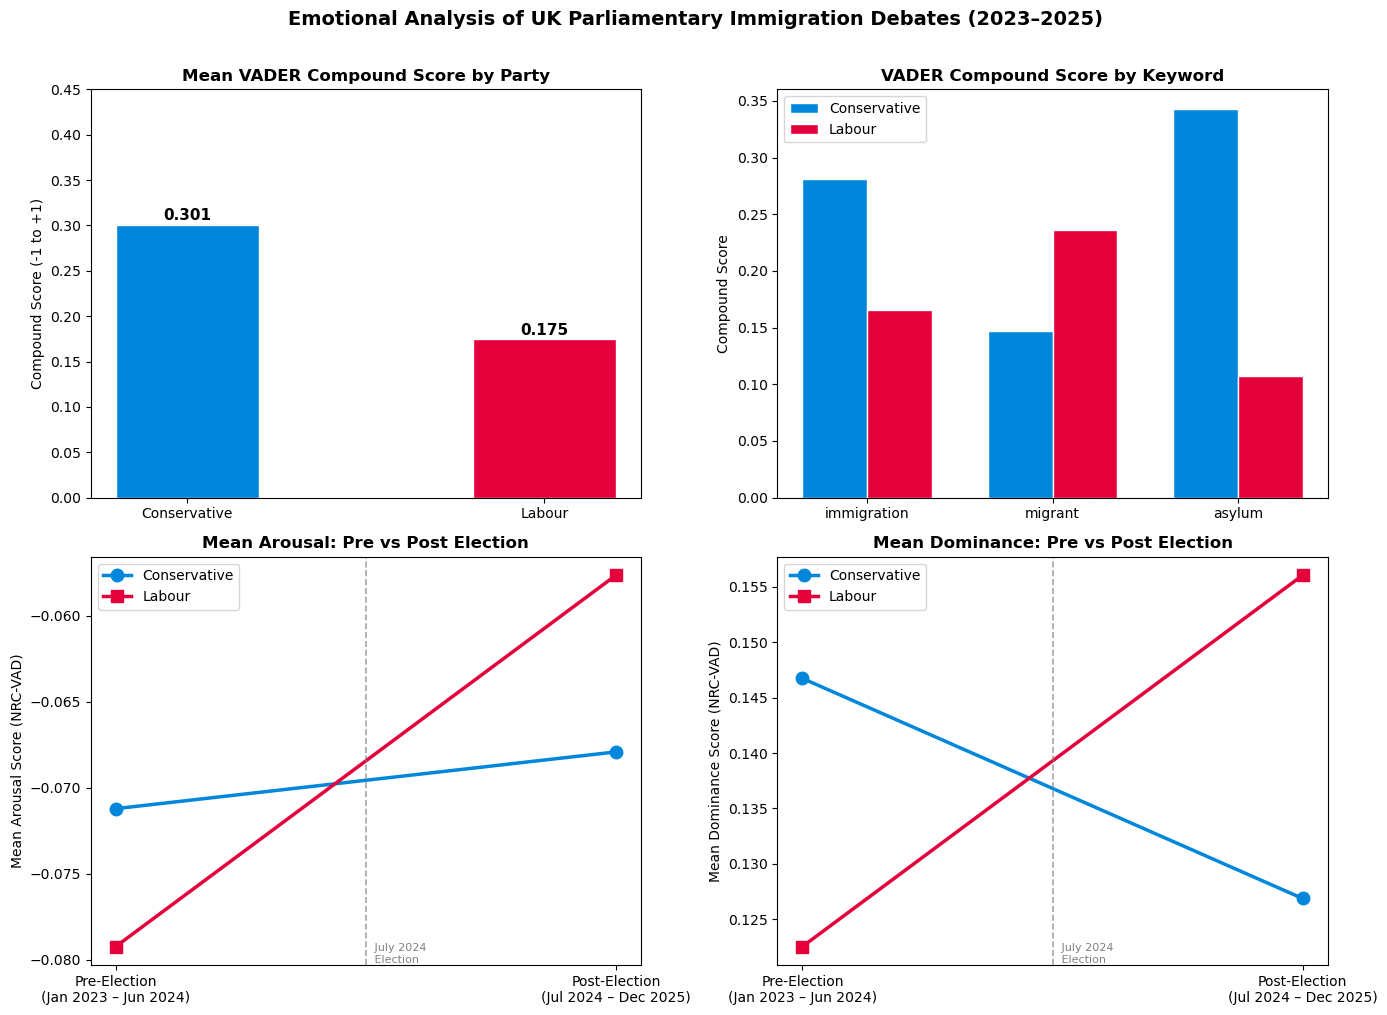

✅ Figure saved: immigration_emotion_analysis.png


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Emotional Analysis of UK Parliamentary Immigration Debates (2023–2025)',
             fontsize=14, fontweight='bold', y=1.01)

CON = '#0087DC'
LAB = '#E4003B'

# ── Plot 1: VADER compound by party ──────────────────────────
ax1 = axes[0, 0]
vals = df.groupby('party')['vader_compound'].mean()
bars = ax1.bar(vals.index, vals.values, color=[CON, LAB], width=0.4, edgecolor='white')
ax1.set_title('Mean VADER Compound Score by Party', fontweight='bold')
ax1.set_ylabel('Compound Score (-1 to +1)')
ax1.set_ylim(0, 0.45)
for bar, v in zip(bars, vals.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{v:.3f}', ha='center', fontsize=11, fontweight='bold')

# ── Plot 2: VADER compound by keyword ────────────────────────
ax2  = axes[0, 1]
x    = np.arange(len(KEYWORDS))
w    = 0.35
con_v= [df[(df['party']=='Conservative')&(df[f'has_{k}'])]['vader_compound'].mean() for k in KEYWORDS]
lab_v= [df[(df['party']=='Labour')      &(df[f'has_{k}'])]['vader_compound'].mean() for k in KEYWORDS]
ax2.bar(x-w/2, con_v, w, label='Conservative', color=CON, edgecolor='white')
ax2.bar(x+w/2, lab_v, w, label='Labour',       color=LAB, edgecolor='white')
ax2.set_title('VADER Compound Score by Keyword', fontweight='bold')
ax2.set_ylabel('Compound Score')
ax2.set_xticks(x); ax2.set_xticklabels(KEYWORDS)
ax2.legend()
ax2.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.4)

# ── Plot 3: Arousal pre vs post election ─────────────────────
ax3     = axes[1, 0]
periods = ['Pre-Election\n(Jan 2023 – Jun 2024)', 'Post-Election\n(Jul 2024 – Dec 2025)']
for party, color, marker in [('Conservative', CON, 'o'), ('Labour', LAB, 's')]:
    vals = [df[(df['party']==party)&(df['period']==p)]['arousal'].mean()
            for p in ['pre_election','post_election']]
    ax3.plot(periods, vals, marker=marker, color=color, linewidth=2.5,
             markersize=9, label=party)
ax3.axvline(x=0.5, color='gray', linestyle='--', linewidth=1.2, alpha=0.7)
ax3.text(0.51, ax3.get_ylim()[0], ' July 2024\n Election', fontsize=8, color='gray', va='bottom')
ax3.set_title('Mean Arousal: Pre vs Post Election', fontweight='bold')
ax3.set_ylabel('Mean Arousal Score (NRC-VAD)')
ax3.legend()

# ── Plot 4: Dominance pre vs post election ───────────────────
ax4 = axes[1, 1]
for party, color, marker in [('Conservative', CON, 'o'), ('Labour', LAB, 's')]:
    vals = [df[(df['party']==party)&(df['period']==p)]['dominance'].mean()
            for p in ['pre_election','post_election']]
    ax4.plot(periods, vals, marker=marker, color=color, linewidth=2.5,
             markersize=9, label=party)
ax4.axvline(x=0.5, color='gray', linestyle='--', linewidth=1.2, alpha=0.7)
ax4.text(0.51, ax4.get_ylim()[0], ' July 2024\n Election', fontsize=8, color='gray', va='bottom')
ax4.set_title('Mean Dominance: Pre vs Post Election', fontweight='bold')
ax4.set_ylabel('Mean Dominance Score (NRC-VAD)')
ax4.legend()

plt.tight_layout()
plt.savefig('immigration_emotion_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Figure saved: immigration_emotion_analysis.png')

## 11. Save Final Dataset

In [13]:
df.to_csv('hansard_immigration_analysis_final.csv', index=False)

print('✅ Saved: hansard_immigration_analysis_final.csv')
print(f'   Rows: {len(df)}  |  Columns: {list(df.columns)}')

print('\n' + '='*65)
print('FULL RESULTS SUMMARY')
print('='*65)

print('\n1. VADER VALENCE')
for party in ['Conservative','Labour']:
    sub  = df[df['party']==party]
    dist = sub['sentiment'].value_counts(normalize=True)*100
    print(f'\n  {party} (n={len(sub)})  mean compound={sub["vader_compound"].mean():.4f}')
    for label, pct in dist.items():
        print(f'    {label:<12}: {pct:.1f}%')

print('\n2. NRC-VAD AROUSAL & DOMINANCE')
print(df.groupby('party')[['arousal','dominance']].agg(['mean','std']).round(4))

print('\n3. INSTITUTIONAL SHIFT')
for party in ['Conservative','Labour']:
    for m in ['arousal','dominance']:
        pre  = df[(df['party']==party)&(df['period']=='pre_election')][m].mean()
        post = df[(df['party']==party)&(df['period']=='post_election')][m].mean()
        print(f'  {party:<15} {m:<12} pre={pre:.4f}  post={post:.4f}  Δ={post-pre:+.4f}')

print('\n4. VADER BY KEYWORD')
for kw in KEYWORDS:
    sub = df[df[f'has_{kw}']==True]
    con = sub[sub['party']=='Conservative']['vader_compound'].mean()
    lab = sub[sub['party']=='Labour']['vader_compound'].mean()
    print(f'  {kw:<15} Conservative={con:.4f}  Labour={lab:.4f}  Δ={con-lab:+.4f}')

✅ Saved: hansard_immigration_analysis_final.csv
   Rows: 2468  |  Columns: ['date', 'speaker', 'text', 'filename', 'party', 'has_immigration', 'has_migrant', 'has_asylum', 'year', 'vader_neg', 'vader_neu', 'vader_pos', 'vader_compound', 'sentiment', 'arousal', 'dominance', 'vad_coverage', 'period']

FULL RESULTS SUMMARY

1. VADER VALENCE

  Conservative (n=1084)  mean compound=0.3009
    positive    : 66.6%
    negative    : 31.4%
    neutral     : 2.0%

  Labour (n=1384)  mean compound=0.1748
    positive    : 60.1%
    negative    : 37.6%
    neutral     : 2.3%

2. NRC-VAD AROUSAL & DOMINANCE
             arousal         dominance        
                mean     std      mean     std
party                                         
Conservative -0.0701  0.0733    0.1400  0.0715
Labour       -0.0652  0.0741    0.1442  0.0707

3. INSTITUTIONAL SHIFT
  Conservative    arousal      pre=-0.0712  post=-0.0679  Δ=+0.0033
  Conservative    dominance    pre=0.1467  post=0.1269  Δ=-0.0198
  Lab

In [14]:
# Verify the exact p-values from the analysis
from scipy import stats

for party in ["Conservative", "Labour"]:
    pre  = df[(df["party"] == party) & (df["period"] == "pre_election")]["arousal"].dropna()
    post = df[(df["party"] == party) & (df["period"] == "post_election")]["arousal"].dropna()
    stat, pval = stats.mannwhitneyu(pre, post, alternative="two-sided")
    print(f"{party}: pre_n={len(pre)}, post_n={len(post)}, p={pval:.4f}")

# Also verify corpus counts
print(f"\nTotal speeches : {len(df)}")
print(f"Conservative   : {len(df[df['party']=='Conservative'])}")
print(f"Labour         : {len(df[df['party']=='Labour'])}")

Conservative: pre_n=718, post_n=366, p=0.6406
Labour: pre_n=487, post_n=897, p=0.0000

Total speeches : 2468
Conservative   : 1084
Labour         : 1384


In [15]:
print(f"Conservative - compound: {df[df['party']=='Conservative']['vader_compound'].mean():.3f}")
print(f"Conservative - pos:      {df[df['party']=='Conservative']['vader_pos'].mean():.3f}")
print(f"Labour - compound:       {df[df['party']=='Labour']['vader_compound'].mean():.3f}")
print(f"Labour - pos:            {df[df['party']=='Labour']['vader_pos'].mean():.3f}")

Conservative - compound: 0.301
Conservative - pos:      0.111
Labour - compound:       0.175
Labour - pos:            0.107
